In [91]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv('../../course_assignments/homework8/state_data.csv')

In [92]:
print(df.shape)
# shape is rectangular, 52 rows and 4 cols
# columns are split by state abbreviation, latitutde, longitude, and the name of the State
# there are 52 rows of 4 entries each, so 204 entries.


(52, 4)


In [93]:
df.head()

,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


In [94]:
df.tail()
#first state is Alaska
#last state is Wyoming
# it might have blank or duplicate rows (?)

,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


In [95]:
med_lat = df["latitude"].median()
med_lon = df["longitude"].median()

print(med_lat)
#39.4355155
print(med_lon)
#-89.093198

39.4355155
-89.093198


In [96]:
df["lat_distance"] = (df["latitude"] - med_lat).abs()
df["lon_distance"] = (df["longitude"] - med_lon).abs()

print(df.shape)
# shape is rectangular, 52 rows and 6 cols

(52, 6)


In [97]:
sorted_lat = df.sort_values(by="lat_distance")
closest_lat_state = sorted_lat.iloc[0]["state"]
closest_lat_dist = sorted_lat.iloc[0]["lat_distance"]
print(f"closest median latitude: {closest_lat_state} by {closest_lat_dist:.2f}")

closest median latitude: CO by 0.11


In [98]:
farthest_lat = df.sort_values(by="lat_distance", ascending=False)
farthest_lat_state = farthest_lat.iloc[0]["state"]
farthest_lat_dist = farthest_lat.iloc[0]["lat_distance"]
print(f"farthest median latitude: {farthest_lat_state} by {farthest_lat_dist:.2f}")

farthest median latitude: AK by 24.15


In [99]:
sorted_lon = df.sort_values(by="lon_distance")
closest_lon_state = sorted_lon.iloc[0]["state"]
closest_lon_dist = sorted_lon.iloc[0]["lon_distance"]
print(f"closest median longitude: {closest_lon_state} by {closest_lon_dist:.2f}")

closest median longitude: IL by 0.31


In [100]:
farthest_lon = df.sort_values(by="lon_distance", ascending=False)
farthest_lon_state = farthest_lon.iloc[0]["state"]
farthest_lon_dist = farthest_lon.iloc[0]["lon_distance"]
print(f"farthest median longitude: {farthest_lon_state} by {farthest_lon_dist:.2f}")

farthest median longitude: HI by 66.57


In [101]:
print(df.idxmin())

state            0
latitude        39
longitude       11
name             1
lat_distance     5
lon_distance    14
dtype: int64


In [102]:
print(df.idxmax())
#I found this function in "Essential basic functionality" on the User Guide tab
#these functions return the index labels of the min and max values

state           51
latitude         0
longitude       39
name            51
lat_distance     0
lon_distance    11
dtype: int64


In [103]:
df = sns.load_dataset('planets')

df.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


In [104]:
print(df.columns[df.isnull().any()])

df = df.dropna()

Index(['orbital_period', 'mass', 'distance'], dtype='object')


In [105]:
print(df.shape)
#shape is rectangle, 498 by 6

(498, 6)


In [106]:
df.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


In [107]:
df.tail()
#the columns are method (how the planets were detected), number (sequential order from how close they are to their sun), orbital period (time it takes for it to orbit their sun), mass (the mass of the planet), distance (distance from us), and year (year discovered maybe?)

,method,number,orbital_period,mass,distance,year
640,Radial Velocity,1,111.70000,2.100,14.90,2009
641,Radial Velocity,1,5.05050,1.068,44.46,2013
642,Radial Velocity,1,311.28800,1.940,17.24,1999
649,Transit,1,2.70339,1.470,178.00,2013
784,Radial Velocity,3,580.00000,0.947,135.00,2012


/var/folders/5d/l5s8xjd16mxfv1qnnr7dl9200000gp/T/ipykernel_29925/1032473405.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


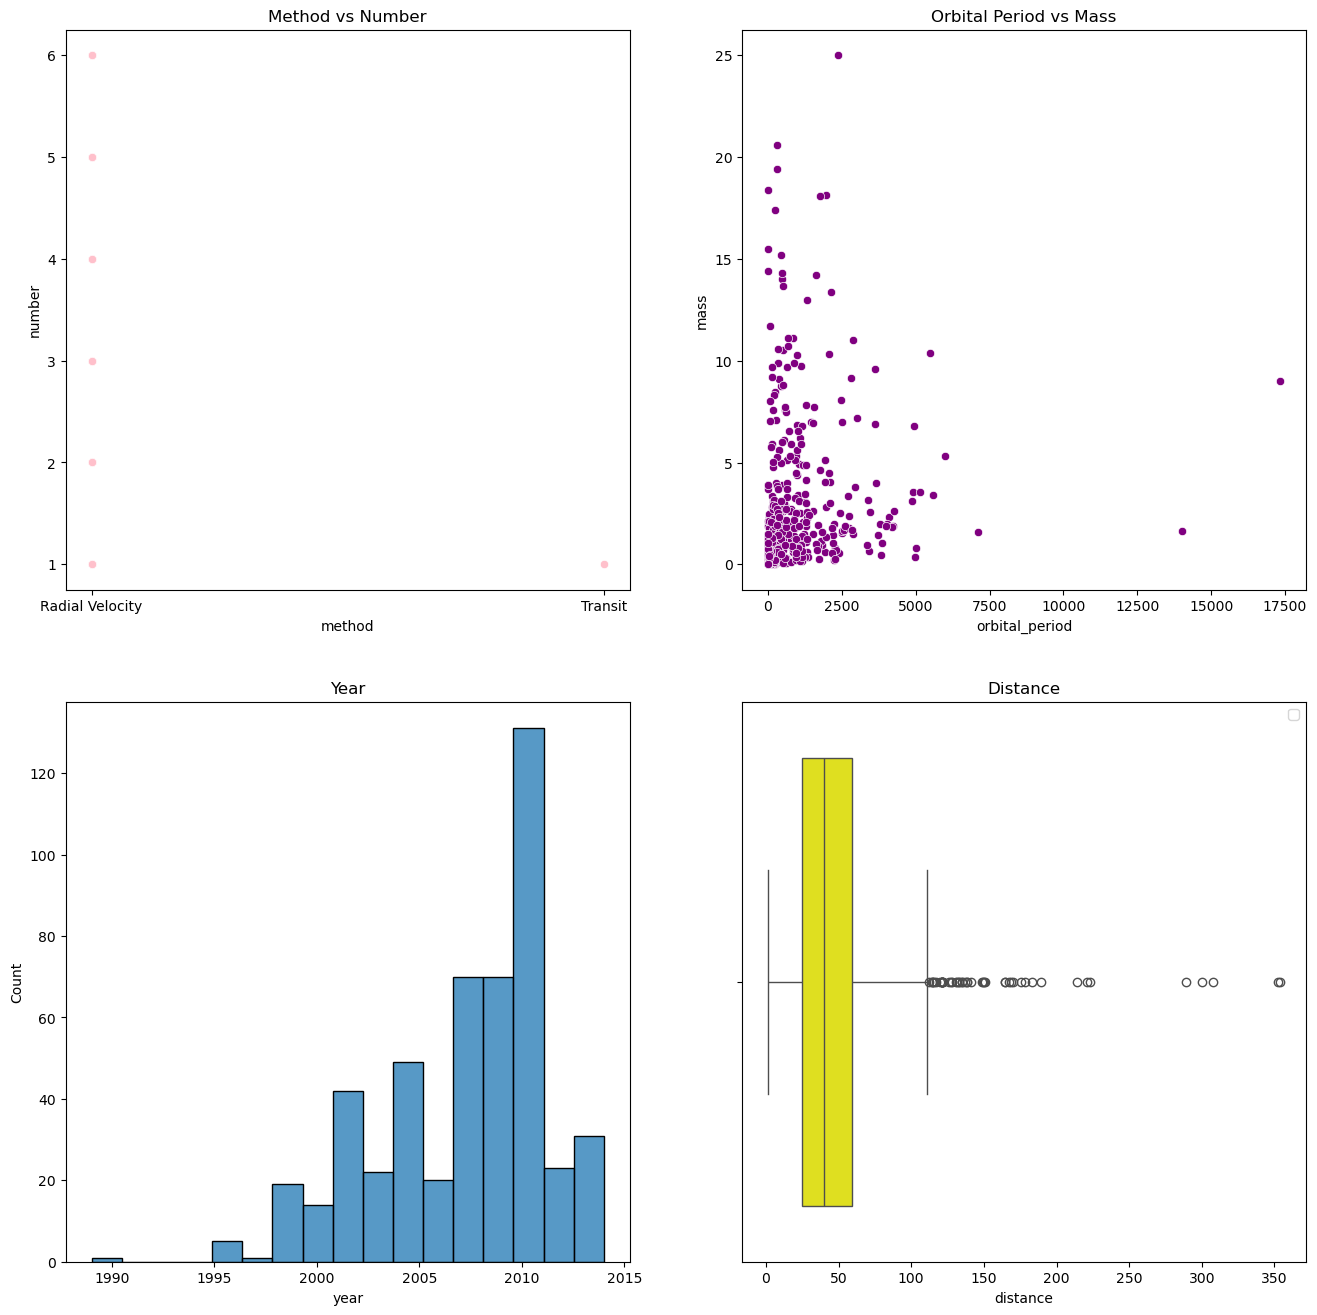

In [108]:
fig, axes = plt.subplots(2, 2, figsize = (16,16))

sns.scatterplot(data = df, x = "method", y = "number", ax = axes[0,0], color = "pink")
axes[0,0].set_title("Method vs Number")

sns.scatterplot(data = df, x = "orbital_period", y = "mass", ax = axes[0,1], color = "purple")
axes[0,1].set_title("Orbital Period vs Mass")

sns.boxplot(data = df, x = "distance", ax = axes[1,1], color = "yellow")
axes[1,1].set_title("Distance")

sns.histplot(data = df, x = "year", ax = axes[1,0])
axes[1,0].set_title("Year")

plt.legend()
plt.show()

#1. number is compared to the method used; i decided to pair these two together in order to see which types of planets are spotted in which ways, and i thought therre would be a trend but there isn't, they're all almost found in the same way
#2. orbital period is compared to mass; i decided to pair these two together to see the plot with kepler's laws in mind. I also should have plotted period to number to see time change by sequential order. I learned the orbital period vs mass is concetrated in one corner.
#3. I did a histogram for year since it is singular variable, and was able to see most planets were discovered around 2010
#4. I did a boxplot for distances since it can have means and more stats stuff. I found the median distance is aroud 40 AU.